In [1]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

import random

In [2]:
# Reproducibility
np.random.seed(42)
random.seed(42)

# Physics
GRAVITY = 9.81
START_X = 0.0
START_Y = 1.5

# Target distance and height ranges
MIN_DISTANCE = 18.0
MAX_DISTANCE = 30.0
MIN_TARGET_HEIGHT = 3.0
MAX_TARGET_HEIGHT = 7.0

print("AI Archer game environment is ready!")
print("Gravity:", GRAVITY, "m/s²")

AI Archer game environment is ready!
Gravity: 9.81 m/s²


In [3]:
def calculate_trajectory(distance, angle_deg, speed, points=200):
    """
    Calculate arrow coordinates until it reaches
    the target's horizontal distance.
    """
    angle = np.radians(angle_deg)

    x = np.linspace(0, distance, points)

    y = (
        START_Y
        + x * np.tan(angle)
        - (GRAVITY * x**2)
        / (2 * speed**2 * np.cos(angle)**2)
    )

    return x, y


def calculate_landing_height(distance, angle_deg, speed):
    """
    Calculate arrow height at the target's x-coordinate.
    """
    angle = np.radians(angle_deg)

    y = (
        START_Y
        + distance * np.tan(angle)
        - (GRAVITY * distance**2)
        / (2 * speed**2 * np.cos(angle)**2)
    )

    return float(y)


print("Projectile physics functions created!")

Projectile physics functions created!


In [4]:
def make_expert_shot(distance, target_height):
    """
    Generate a mathematically calculated shot
    aimed at the target center.
    """
    angle = (
        42.0
        + 0.55 * (distance - 24.0)
        + 1.5 * (target_height - 5.0)
    )

    angle = np.clip(angle, 30.0, 55.0)

    angle_rad = np.radians(angle)

    denominator = 2 * np.cos(angle_rad)**2 * (
        START_Y + distance * np.tan(angle_rad) - target_height
    )

    speed = np.sqrt(GRAVITY * distance**2 / denominator)

    return angle, speed


# Create many different target situations.
number_of_samples = 5000

distances = np.random.uniform(
    MIN_DISTANCE, MAX_DISTANCE, number_of_samples
)

target_heights = np.random.uniform(
    MIN_TARGET_HEIGHT, MAX_TARGET_HEIGHT, number_of_samples
)

X_data = []
y_data = []

for distance, target_height in zip(distances, target_heights):
    angle, speed = make_expert_shot(distance, target_height)

    # Inputs: target distance and target height.
    X_data.append([distance, target_height])

    # Outputs: recommended angle and initial speed.
    y_data.append([angle, speed])

X_data = np.array(X_data)
y_data = np.array(y_data)

print("Training samples:", len(X_data))
print("Input features:", X_data.shape[1])
print("Output values:", y_data.shape[1])

print("\nExample input:", X_data[0])
print("Example output (angle, speed):", y_data[0])

Training samples: 5000
Input features: 2
Output values: 2

Example input: [22.49448143  4.57454208]
Example output (angle, speed): [40.53377791 16.3057694 ]


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.20,
    random_state=42
)

# Normalize inputs and outputs.
input_scaler = StandardScaler()
output_scaler = StandardScaler()

X_train_scaled = input_scaler.fit_transform(X_train)
X_test_scaled = input_scaler.transform(X_test)

y_train_scaled = output_scaler.fit_transform(y_train)

# Create the ANN.
ann = MLPRegressor(
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.003,
    max_iter=1500,
    early_stopping=True,
    random_state=42
)

# Train the network.
ann.fit(X_train_scaled, y_train_scaled)

# Test predictions.
test_predictions_scaled = ann.predict(X_test_scaled)
test_predictions = output_scaler.inverse_transform(
    test_predictions_scaled
)

angle_error = mean_absolute_error(
    y_test[:, 0], test_predictions[:, 0]
)

speed_error = mean_absolute_error(
    y_test[:, 1], test_predictions[:, 1]
)

print("ANN training completed!")
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Mean absolute angle error:", round(angle_error, 3), "degrees")
print("Mean absolute speed error:", round(speed_error, 3), "m/s")

ANN training completed!
Training examples: 4000
Testing examples: 1000
Mean absolute angle error: 0.013 degrees
Mean absolute speed error: 0.006 m/s


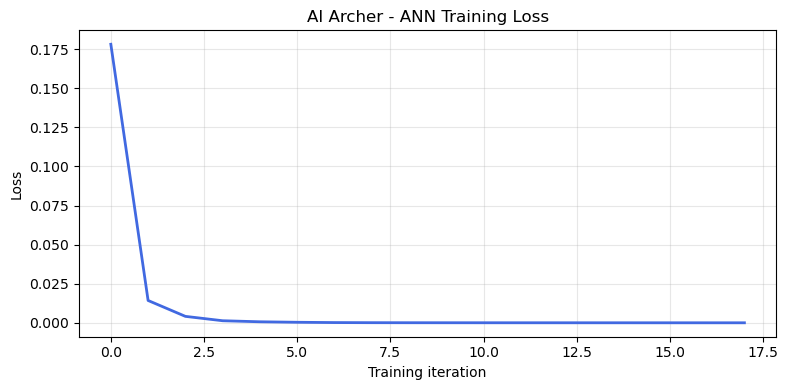

In [6]:
plt.figure(figsize=(8, 4))

plt.plot(ann.loss_curve_, color="royalblue", linewidth=2)

plt.title("AI Archer - ANN Training Loss")
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
def ai_aim(distance, target_height):
    # Prepare the target information.
    target_input = np.array([[distance, target_height]])

    # Normalize input.
    target_input_scaled = input_scaler.transform(target_input)

    # Ask the ANN to predict angle and speed.
    prediction_scaled = ann.predict(target_input_scaled)

    # Convert the prediction back to real units.
    prediction = output_scaler.inverse_transform(
        prediction_scaled
    )[0]

    angle = float(np.clip(prediction[0], 20, 70))
    speed = float(np.clip(prediction[1], 5, 40))

    return angle, speed


# Test the AI with a sample target.
test_distance = 25.0
test_height = 5.0

predicted_angle, predicted_speed = ai_aim(
    test_distance, test_height
)

print("Target distance:", test_distance, "m")
print("Target height:", test_height, "m")
print("AI predicted angle:", round(predicted_angle, 2), "degrees")
print("AI predicted speed:", round(predicted_speed, 2), "m/s")

predicted_height = calculate_landing_height(
    test_distance, predicted_angle, predicted_speed
)

print("Predicted arrow height at target:",
      round(predicted_height, 2), "m")
print("Actual target height:", test_height, "m")

Target distance: 25.0 m
Target height: 5.0 m
AI predicted angle: 42.52 degrees
AI predicted speed: 17.04 m/s
Predicted arrow height at target: 4.99 m
Actual target height: 5.0 m


In [8]:
def calculate_score(landing_height, target_height):
    error = abs(landing_height - target_height)

    if landing_height < 0:
        return 0

    if error <= 0.25:
        return 10
    elif error <= 0.60:
        return 8
    elif error <= 1.00:
        return 5
    elif error <= 1.50:
        return 2
    else:
        return 0


def draw_game(distance, target_height, angle, speed, score, mode):
    x, y = calculate_trajectory(distance, angle, speed)

    landing_height = calculate_landing_height(
        distance, angle, speed
    )

    fig, ax = plt.subplots(figsize=(12, 5))

    # Ground
    ax.fill_between(
        [-2, distance + 3], 0, -0.4,
        color="saddlebrown", alpha=0.8
    )
    ax.axhline(0, color="darkgreen", linewidth=2)

    # Draw a simple archer.
    ax.plot([-0.2, 0.3], [0.5, 0.5],
            color="black", linewidth=4)
    ax.plot([0, 0], [0.5, 1.5],
            color="navy", linewidth=5)
    ax.plot([-0.3, 0.3], [0.5, 0.0],
            color="black", linewidth=3)
    ax.plot([0, 0.3], [0.5, 0.0],
            color="black", linewidth=3)

    # Head
    ax.add_patch(
        Circle((0, 1.75), 0.25,
               color="orange", zorder=5)
    )

    # Bow
    bow_y = np.linspace(1.1, 2.1, 50)
    bow_x = 0.45 + 0.22 * np.sin(
        np.linspace(0, np.pi, 50)
    )
    ax.plot(bow_x, bow_y, color="saddlebrown",
            linewidth=3)

    # Target stand
    ax.plot(
        [distance, distance],
        [0, target_height - 1.5],
        color="dimgray", linewidth=4
    )

    # Target rings
    ring_colors = ["red", "blue", "black", "gold"]
    ring_radii = [1.5, 1.0, 0.6, 0.25]

    for radius, color in zip(ring_radii, ring_colors):
        ax.add_patch(
            Circle(
                (distance, target_height),
                radius,
                fill=False,
                edgecolor=color,
                linewidth=3
            )
        )

    # Arrow trajectory. Stop displaying the path at ground level.
    valid = y >= 0
    ax.plot(
        x[valid], y[valid],
        color="darkorange", linewidth=2,
        label="Arrow trajectory"
    )

    # Show the landing point if the arrow reaches the target plane.
    if landing_height >= 0:
        ax.scatter(
            [distance], [landing_height],
            color="black", s=45, zorder=6,
            label="Arrow at target distance"
        )

    ax.set_xlim(-2, distance + 3)
    ax.set_ylim(0, max(9, target_height + 3, np.max(y) + 1))
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Horizontal distance (m)")
    ax.set_ylabel("Height (m)")
    ax.set_title(
        f"{mode} | Angle: {angle:.1f}° | "
        f"Speed: {speed:.1f} m/s | Score: {score}"
    )

    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


print("Graphics and scoring functions created!")

Graphics and scoring functions created!


          AI ARCHER GAME
1. Manual mode
2. AI mode


Choose mode (1 or 2):  1



========== ROUND 1 ==========
Target distance: 25.67 m
Target height: 3.10 m


Enter angle (20 to 70 degrees):  40
Enter speed (5 to 40 m/s):  40


Arrow height at target: 19.60 m
Vertical error: +16.50 m
Round score: 0/10
Missed the target!


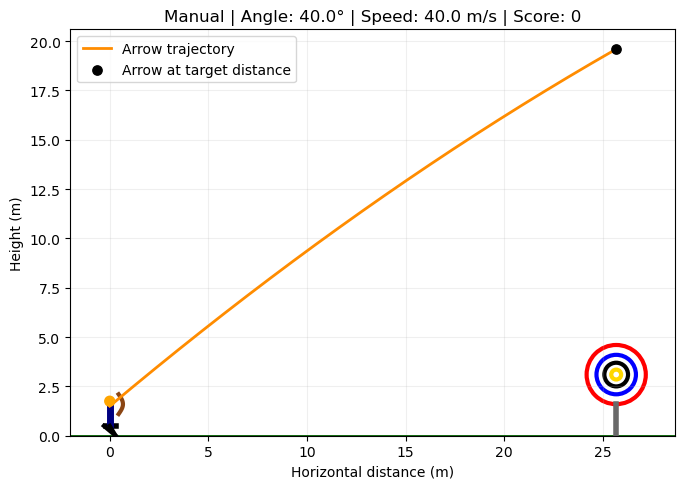

Total score: 0/50

========== ROUND 2 ==========
Target distance: 21.30 m
Target height: 3.89 m


Enter angle (20 to 70 degrees):  20
Enter speed (5 to 40 m/s):  30


Arrow height at target: 6.45 m
Vertical error: +2.56 m
Round score: 0/10
Missed the target!


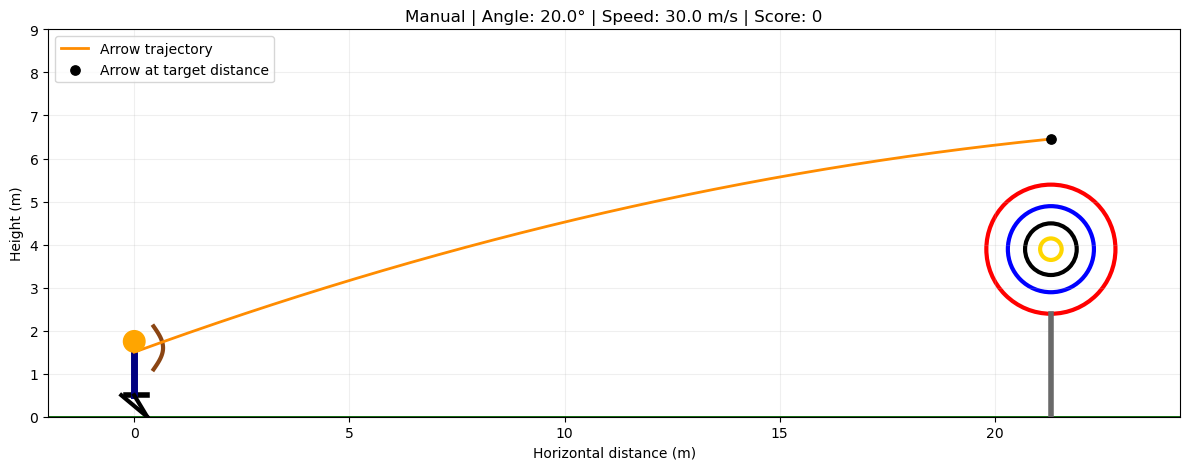

Total score: 0/50

========== ROUND 3 ==========
Target distance: 26.84 m
Target height: 5.71 m


Enter angle (20 to 70 degrees):  25
Enter speed (5 to 40 m/s):  15


Arrow height at target: -5.10 m
Vertical error: -10.81 m
Round score: 0/10
Missed the target!


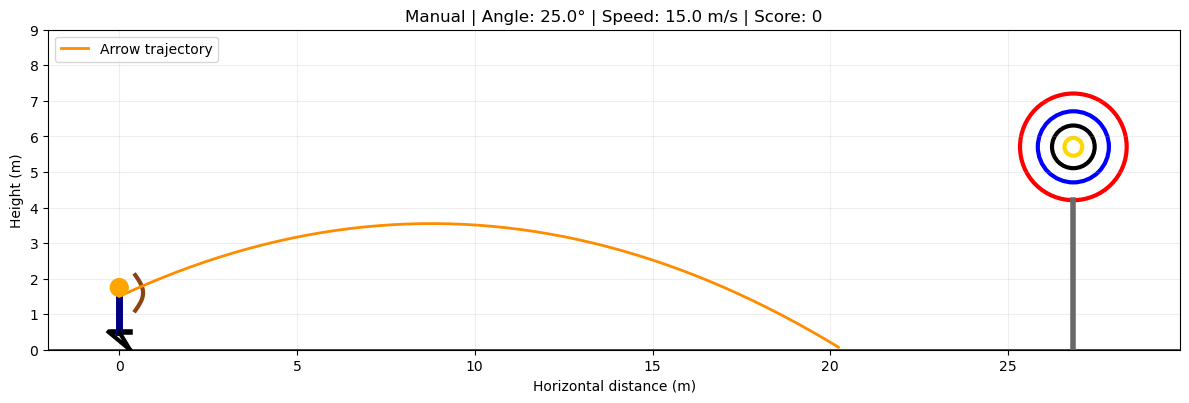

Total score: 0/50

========== ROUND 4 ==========
Target distance: 28.71 m
Target height: 3.35 m


Enter angle (20 to 70 degrees):  30
Enter speed (5 to 40 m/s):  15


Arrow height at target: -5.88 m
Vertical error: -9.23 m
Round score: 0/10
Missed the target!


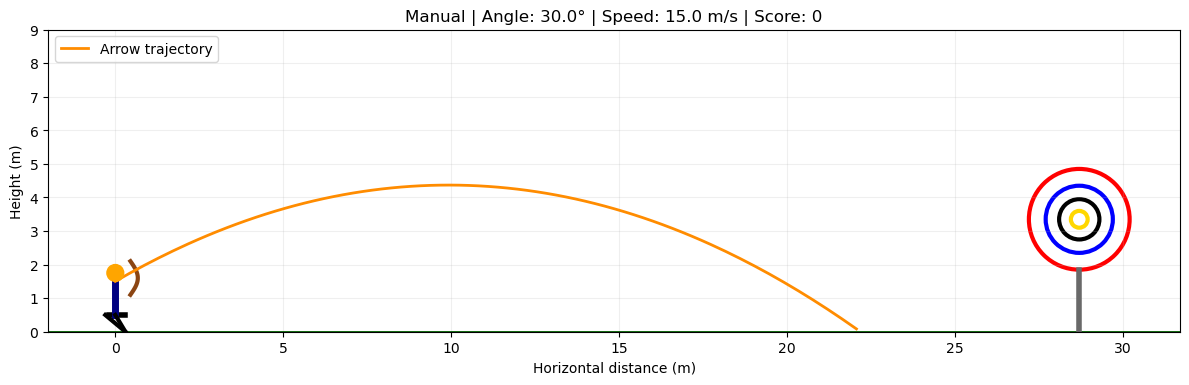

Total score: 0/50

========== ROUND 5 ==========
Target distance: 23.06 m
Target height: 3.12 m


Enter angle (20 to 70 degrees):  25
Enter speed (5 to 40 m/s):  25


Arrow height at target: 7.17 m
Vertical error: +4.05 m
Round score: 0/10
Missed the target!


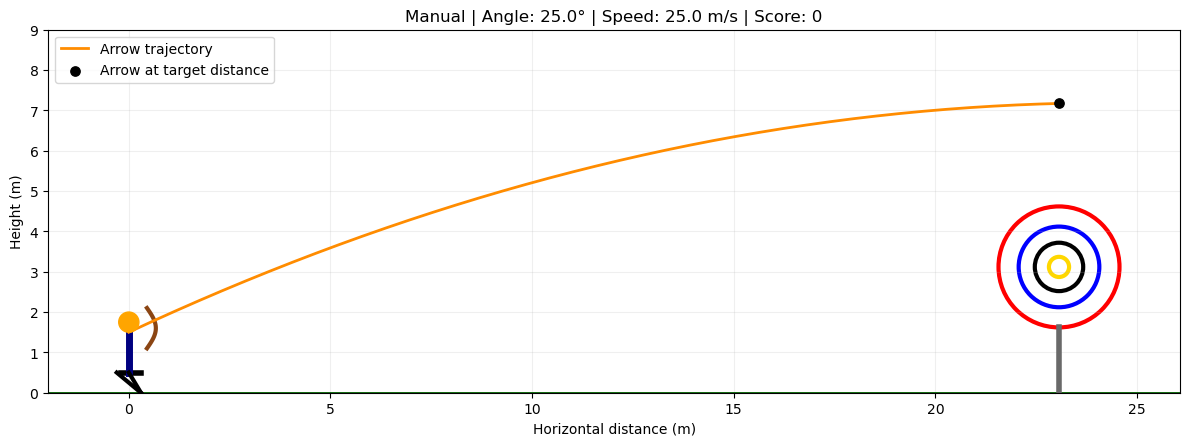

Total score: 0/50

             GAME OVER
Mode: Manual
Round scores: [0, 0, 0, 0, 0]
Final score: 0 / 50
Keep practicing!


In [9]:
print("=" * 45)
print("          AI ARCHER GAME")
print("=" * 45)

print("1. Manual mode")
print("2. AI mode")

mode_choice = input("Choose mode (1 or 2): ").strip()

if mode_choice not in ("1", "2"):
    print("Invalid choice. Please run this cell again.")
else:
    mode_name = "Manual" if mode_choice == "1" else "AI"

    total_score = 0
    round_scores = []

    for round_number in range(1, 6):
        print(f"\n========== ROUND {round_number} ==========")

        # New target for this round.
        distance = random.uniform(
            MIN_DISTANCE, MAX_DISTANCE
        )
        target_height = random.uniform(
            MIN_TARGET_HEIGHT, MAX_TARGET_HEIGHT
        )

        print(f"Target distance: {distance:.2f} m")
        print(f"Target height: {target_height:.2f} m")

        if mode_choice == "1":
            try:
                angle = float(
                    input("Enter angle (20 to 70 degrees): ")
                )
                speed = float(
                    input("Enter speed (5 to 40 m/s): ")
                )

                if not (20 <= angle <= 70 and 5 <= speed <= 40):
                    print("Values outside the allowed range.")
                    print("This round receives zero points.")
                    round_scores.append(0)
                    continue

            except ValueError:
                print("Invalid input. This round receives zero points.")
                round_scores.append(0)
                continue

        else:
            angle, speed = ai_aim(distance, target_height)

            print(f"ANN angle prediction: {angle:.2f} degrees")
            print(f"ANN speed prediction: {speed:.2f} m/s")

        # Simulate the shot.
        landing_height = calculate_landing_height(
            distance, angle, speed
        )

        score = calculate_score(
            landing_height, target_height
        )

        vertical_error = landing_height - target_height

        print(f"Arrow height at target: {landing_height:.2f} m")
        print(f"Vertical error: {vertical_error:+.2f} m")
        print(f"Round score: {score}/10")

        if score == 10:
            print("Bullseye!")
        elif score > 0:
            print("Target hit!")
        else:
            print("Missed the target!")

        draw_game(
            distance, target_height,
            angle, speed, score, mode_name
        )

        total_score += score
        round_scores.append(score)

        print(f"Total score: {total_score}/50")

    print("\n" + "=" * 45)
    print("             GAME OVER")
    print("=" * 45)
    print("Mode:", mode_name)
    print("Round scores:", round_scores)
    print("Final score:", total_score, "/ 50")

    if total_score >= 40:
        print("Excellent archery!")
    elif total_score >= 25:
        print("Good shooting!")
    else:
        print("Keep practicing!")

In [10]:
%pip install ipywidgets matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.3/217.3 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 5.3 MB/s eta 0:00:00a 0:00:01m
Note: you may need to restart the kernel to use updated packages.


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from matplotlib.patches import Circle
from matplotlib.animation import FuncAnimation
import random

# Game settings
GRAVITY = 9.81
START_Y = 1.5

target_distance = random.uniform(20, 28)
target_height = random.uniform(3.5, 6.5)

total_score = 0
shots_taken = 0

# Interactive controls
angle_slider = widgets.FloatSlider(
    value=42, min=20, max=70, step=1,
    description="Angle:", continuous_update=False
)

power_slider = widgets.FloatSlider(
    value=20, min=8, max=35, step=1,
    description="Power:", continuous_update=False
)

shoot_button = widgets.Button(
    description="🏹 SHOOT!",
    button_style="success",
    layout=widgets.Layout(width="150px", height="42px")
)

ai_button = widgets.Button(
    description="🧠 AI AIM",
    button_style="info",
    layout=widgets.Layout(width="150px", height="42px")
)

new_target_button = widgets.Button(
    description="🎯 New Target",
    button_style="warning",
    layout=widgets.Layout(width="150px", height="42px")
)

game_output = widgets.Output()
status = widgets.HTML()

def get_landing(angle_deg, speed, distance):
    angle = np.radians(angle_deg)
    return START_Y + distance * np.tan(angle) - (
        GRAVITY * distance**2
        / (2 * speed**2 * np.cos(angle)**2)
    )

def get_points(height):
    error = abs(height - target_height)
    if height < 0 or error > 1.5:
        return 0
    elif error <= 0.25:
        return 10
    elif error <= 0.60:
        return 8
    elif error <= 1.00:
        return 5
    return 2

def draw_scene(angle=None, speed=None, animate=False):
    fig, ax = plt.subplots(figsize=(11, 5))

    # Sky and grassy landscape
    ax.set_facecolor("#bde9ff")
    ax.axhspan(-1, 0, color="#65ad50")
    ax.axhline(0, color="#397c36", linewidth=2)

    # Decorative clouds
    ax.text(5, 9, "☁", fontsize=30, color="white")
    ax.text(target_distance * 0.48, 10, "☁",
            fontsize=25, color="white")

    # Archer body, legs, and head
    ax.plot([-0.2, 0.2], [1.1, 1.1],
            color="#173d70", linewidth=7)
    ax.plot([0, -0.4], [1.1, 0.1],
            color="#173d70", linewidth=5)
    ax.plot([0, 0.4], [1.1, 0.1],
            color="#173d70", linewidth=5)
    ax.add_patch(Circle((0, 1.85), 0.28,
                        color="#f0b77b", zorder=5))
    ax.plot([0, 0.35], [1.5, 2.0],
            color="#173d70", linewidth=5)

    # Bow
    by = np.linspace(1.2, 2.5, 60)
    bx = 0.45 + 0.3 * np.sin(np.linspace(0, np.pi, 60))
    ax.plot(bx, by, color="#784421", linewidth=4)
    ax.plot([bx[0], bx[-1]], [by[0], by[-1]],
            color="#333333", linewidth=1)

    # Target stand and rings
    ax.plot([target_distance, target_distance],
            [0, target_height - 1.5],
            color="#795548", linewidth=5)

    for radius, color in [
        (1.5, "white"), (1.1, "#2674d9"),
        (0.7, "#e84141"), (0.3, "#ffdb35")
    ]:
        ax.add_patch(Circle(
            (target_distance, target_height),
            radius, facecolor=color,
            edgecolor="black", linewidth=1.2,
            zorder=4
        ))

    ax.set_xlim(-2, target_distance + 3)
    ax.set_ylim(-0.5, 11)
    ax.set_xlabel("Distance (metres)")
    ax.set_ylabel("Height (metres)")
    ax.set_title(
        f"AI ARCHER  |  Target: {target_distance:.1f} m"
    )
    ax.grid(alpha=0.15)

    if angle is not None and speed is not None:
        theta = np.radians(angle)
        flight_time = target_distance / (
            speed * np.cos(theta)
        )
        times = np.linspace(0, flight_time, 100)

        x = speed * np.cos(theta) * times
        y = START_Y + speed * np.sin(theta) * times \
            - 0.5 * GRAVITY * times**2

        valid = y >= 0

        line, = ax.plot([], [], color="#ff6b00",
                        linewidth=2.5)
        arrow_point, = ax.plot([], [], "o",
                               color="#222222", markersize=7)

        def update(frame):
            line.set_data(x[:frame + 1][valid[:frame + 1]],
                          y[:frame + 1][valid[:frame + 1]])
            arrow_point.set_data([x[frame]], [max(0, y[frame])])
            return line, arrow_point

        if animate:
            animation = FuncAnimation(
                fig, update, frames=len(times),
                interval=25, blit=False, repeat=False
            )
            display(HTML(animation.to_jshtml()))
        else:
            update(len(times) - 1)
            display(fig)

        plt.close(fig)
    else:
        display(fig)
        plt.close(fig)

def refresh_idle():
    with game_output:
        clear_output(wait=True)
        draw_scene()

def shoot_game(_):
    global total_score, shots_taken

    angle = angle_slider.value
    speed = power_slider.value

    landing = get_landing(angle, speed, target_distance)
    score = get_points(landing)

    total_score += score
    shots_taken += 1

    with game_output:
        clear_output(wait=True)
        draw_scene(angle, speed, animate=True)

    status.value = (
        f"<h3>🎯 Shot result: {score} points</h3>"
        f"<b>Shots:</b> {shots_taken} &nbsp; | &nbsp; "
        f"<b>Total score:</b> {total_score} &nbsp; | &nbsp; "
        f"<b>Landing height:</b> {landing:.2f} m"
    )

def ai_aim_game(_):
    if "ai_aim" not in globals():
        status.value = (
            "<b>Train the ANN first by running your training cells.</b>"
        )
        return

    angle, speed = ai_aim(target_distance, target_height)
    angle_slider.value = float(angle)
    power_slider.value = float(speed)

    status.value = (
        f"<b>🧠 ANN prediction:</b> "
        f"Angle {angle:.1f}° | Power {speed:.1f} m/s. "
        "Press SHOOT to fire!"
    )

def change_target(_):
    global target_distance, target_height

    target_distance = random.uniform(20, 28)
    target_height = random.uniform(3.5, 6.5)

    refresh_idle()
    status.value = (
        f"<b>New target!</b> Distance: {target_distance:.1f} m "
        f"| Height: {target_height:.1f} m"
    )

shoot_button.on_click(shoot_game)
ai_button.on_click(ai_aim_game)
new_target_button.on_click(change_target)

controls = widgets.VBox([
    widgets.HTML("<h2>🏹 AI ARCHER</h2>"),
    widgets.HTML(
        "<p>Adjust your aim, shoot, or ask the ANN to aim for you.</p>"
    ),
    angle_slider,
    power_slider,
    widgets.HBox([shoot_button, ai_button]),
    new_target_button,
    status,
    game_output
])

display(controls)
refresh_idle()

In [12]:
import ipywidgets as widgets
from IPython.display import display

test_button = widgets.Button(
    description="TEST BUTTON",
    button_style="success"
)

display(test_button)

Button(button_style='success', description='TEST BUTTON', style=ButtonStyle())

In [13]:
display(controls)

In [14]:
%pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [15]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider(description="Test slider:"))

IntSlider(value=0, description='Test slider:')